In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import eigh
from scipy.special import genlaguerre, factorial
from scipy.constants import h, electron_volt, value

h_eV = h/electron_volt
mu_B_eV = value('Bohr magneton')/electron_volt

hbar = 1.0
m = 1.0
e = 1.0
epsilon0 = 1/(4*np.pi)
alpha = 1/137
Ha_to_eV = 27.211386


orbitals_list = {0: 's', 1: 'p', 2: 'd', 3: 'f', 4: 'g'}

# Temas Selectos de Física Atómica I
## Actividad 4. Solución al Átomo de Hidrógeno
 Ángel André Aguilar Contreras

In [2]:
class potential: # Definimos una clase para guardar el potencial
    def hydrogen_radial(r, l=0, Z=1.0):
        """
        Potencial efectivo del átomo hidrogeneroide.
        """
        V_coulomb = -Z*(e**2)/(4*np.pi*epsilon0*r)
        V_centrifugal = (l*(l + 1)*hbar**2)/(2.0*m*r**2)
        return V_coulomb + V_centrifugal

In [3]:
class solve:
    def hamiltonian(dr, V, N):
        """
        Resuelve la matriz del Hamiltoniano considerando la parte cinética y la parte potencial.
        Calculamos la parte cinética del Hamiltoniano a partir de diferencias finitas centradas.
        d^2(Psi)/dx^2 \approx (Psi_{i+1} - 2 Psi_{i} + Psi_{i-1})/(delta x^2)
        """

        """ Crear la matriz para emplearla en la ecuación de Schrodinger discretizada. """
        constant = -hbar**2 / (2 * m * dr**2) # constante fuera del diferencial -h^2/2m 1/dx^2
        main_diag = -2*np.ones(N) # multiplicado por -2 sobre la diagonal
        off_diag = np.ones(N-1) # multiplicado por 1 en las secundarias
        T = constant*(np.diag(main_diag) + np.diag(off_diag, k=1) + np.diag(off_diag, k=-1))
        H = T + np.diag(V) # Hamiltoniano
        #plot.heatmap(H) # Graficación de la Matriz Hamiltoniana
        return H
        
    @staticmethod
    def get_orbital(n, l, r, Z=1.0, N = 100):
        """
        Recupera automáticamente la energía E, función reducida u(r) 
        y función radial R(r) para un número cuántico (n, l) específico.
        """
        if l >= n: raise ValueError(f"Error. l ({l}) debe ser estrictamente menor que n ({n}).")
            
        dr = r[1] - r[0]
        V = potential.hydrogen_radial(r, l=l, Z=Z)
        """
        1. Utilizando la parte radial del Hamiltoniano del átomo de hidrogeno, 
        crear la matriz para emplearla en la ecuación de Schrodinger discretizada.
        """
        H = solve.hamiltonian(dr, V, N)
        """
        2. Utilice herramientas numéricas de algebra lineal para resolver la ecuación de
        eigenvalores. Normalice las eigenfunciones calculadas.
        """
        eigenvalues, eigenfunctions = eigh(H)
        norm = np.trapezoid(eigenfunctions**2, r, axis=0) 
        eigenfunctions /= np.sqrt(norm) 
        
        node = n - l - 1 # Índice de nodo radial i = n - l - 1
        
        energy = eigenvalues[node]
        radial_reduced = eigenfunctions[:, node]
        
        radial = radial_reduced / r
        label = f"{n}{orbitals_list.get(l, f'l={l}')}"
        
        return {'n': n, 'l': l, 'label': label, 'energy': energy, 'radial_reduced': radial_reduced, 'radial': radial}

    @staticmethod
    def get_orbitals_upto(n_max, r, Z=1.0, N = 100):
        """
        Genera una lista con todos los orbitales ordenados desde n=1 hasta n_max 
        barriendo l desde 0 hasta n-1 (ej. 1s, 2s, 2p, 3s, 3p, 3d...).
        """
        orbitals = []
        for n in range(1, n_max + 1):
            for l in range(n):
                orb = solve.get_orbital(n=n, l=l, r=r, Z=Z, N=N)
                orbitals.append(orb)
        return orbitals

    @staticmethod
    def get_expval(n, l, r, Z=1.0, N=100):
        """
        5.  Calcular el valor esperado de〈1/r^3〉para obtener la estructura fina del átomo de hidrógeno.
        """
        orb = solve.get_orbital(n=n, l=l, r=r, Z=Z, N=N)
        dr = r[1]- r[0]
        exp_val = np.sum((orb['radial_reduced']**2)*(1/r**3))*dr
        return exp_val
        
    @staticmethod
    def fine_structure(n, l, r, s, Z=1.0, N=100, verbose = True):
        if verbose: 
            print(f":::   CORRECCIÓN DE ESTRUCTURA FINA PARA EL ESTADO {n}{orbitals_list.get(l, f'l={l}').upper()} CON Z={Z}   :::")
        if (l==0): 
            print(f"Para l=0, no hay acoplamiento espín-órbita. Por lo que no hay desdoblamiento \n")
            return
        num_expval = solve.get_expval(n=n, l=l, r=r, Z=Z, N=N)
        ana_expval = analytical.get_expval(n=n, l=l, Z=Z)
        
        j1, j2 = l-s, l+s
        E1 = (Z**2*alpha**2/4)*num_expval*(j1*(j1+1)- l*(l+1) - s*(s+1))*Ha_to_eV
        E2 = (Z**2*alpha**2/4)*num_expval*(j2*(j2+1)- l*(l+1) - s*(s+1))*Ha_to_eV
        dE = np.abs(E2-E1)

        if verbose:
            print(f"Valor numérico esperado de <1/r³>: {num_expval:.6f} a\u2080⁻³")
            print(f"Valor analítico esperado de <1/r³>: {ana_expval:.6f} a\u2080⁻³ \n")
            print(f"Energía del nivel {n}{orbitals_list.get(l, f'l={l}').upper()}_{int(j1*2)}/2: {E1*1e3:.6f} meV")
            print(f"Energía del nivel {n}{orbitals_list.get(l, f'l={l}').upper()}_{int(j2*2)}/2: {E2*1e3:.6f} meV")
            print(f"Separación energética de la estructura fina: {dE*1e3:.6f} meV ({dE/h_eV*1e-9:.4f} GHz) \n")

        label = f"{n}{orbitals_list.get(l, f'l={l}').upper()}"
        return {'n': n, 'l': l, 'label': label, 'j1':j1, 'j2':j2, 'E1': E1, 'E2': E2}

    def fine_structure_upto(n_max, r, s=1/2, Z=1.0, N=1.0):
        for n in range(1, n_max+1):
            for l in range(n):
                _ = solve.fine_structure(n=n, l=l, r=r, s=s, Z=Z, N=N)

In [4]:
class analytical:
    @staticmethod
    def radial(n, l, r, Z=1.0):
        """Calcula la función radial analítica R_{n,l}(r) exacta."""
        rho = (2.0 * Z * r) / n
        norm = np.sqrt((2.0 * Z / n)**3 * factorial(n - l - 1) / (2.0 * n * factorial(n + l))) # Factor de normalización
        L = genlaguerre(n - l - 1, 2 * l + 1) # Polinomio asociado de Laguerre 
        return norm * np.exp(-rho / 2.0) * (rho**l) * L(rho)

    @staticmethod
    def radial_reduced(n, l, r, Z=1.0):
        """Calcula la función u_{n,l}(r) = r * R(r)."""
        return r * analytical.radial(n, l, r, Z)

    @staticmethod
    def energy(n, Z=1.0):
        """Energía analítica del átomo de hidrógeno: E_n = -Z^2 / (2 * n^2) en Hartree."""
        return -0.5 * (Z**2) / (n**2)

    @staticmethod
    def get_orbital(n,l,r,Z = 1.0):
        radial = analytical.radial(n, l, r, Z)
        radial_reduced = analytical.radial_reduced(n, l, r, Z)
        energy = analytical.energy(n,Z)
        label = f"{n}{orbitals_list.get(l, f'l={l}')}"
        return {'n': n, 'l': l, 'label': label, 'energy': energy, 'radial_reduced': radial_reduced, 'radial': radial}

    @staticmethod
    def get_expval(n, l, Z=1.0):
        expval = 1/((n**3)*l*(l+0.5)*(l+1))
        return expval

In [5]:
class plot:
    def heatmap(H):
        """
        Grafica la matriz en un mapa de color para visualizar los elementos relevantes. 
        """
        fig = plt.figure(figsize=(6, 6))
        im = plt.imshow(H, cmap='inferno', aspect='equal')
        fig.colorbar(im, fraction=0.046, pad=0.04, label="Energía")
        plt.title('Heatmap de la Matriz Hamiltoniana')
        plt.xlabel('Columna [Índice i]')
        plt.ylabel('Fila [Índice j]')
        
        plt.show()
        
    def solution(orbitals, r, **kargs):
        """
        Grafica los orbitales respecto a laa coordenada radial con sus respectivas energías.
        """
        label, xlim, ylim = kargs.get('label', ''), kargs.get('xlim', (-1,1)) ,kargs.get('ylim', (-1,1))
        
        plt.figure(figsize=(11, 6))

        """
        3. Grafique las funciones de onda y las energías del sistema. Como mínimo, utilice los primeros 5 estados.
        """
        for i, orb in enumerate(orbitals):
            (line,) = plt.plot(r, np.abs(orb['radial_reduced'])**2 + orb['energy'], 
                               label = f"$|u(r)|^2$, {orb['label']:<3}, E = {orb['energy']:.4f} Ha")
            color = line.get_color()
            plt.hlines(orb['energy'], r[0], r[-1], color = color, linestyle=':', alpha=0.5)
            
        plt.xlim(xlim)
        plt.ylim(ylim)
        
        plt.xlabel('Distancia radial [r] ($a_0$)')
        plt.ylabel('Energias y norma de las funciones radiales')
        plt.title(f'Soluciones a Átomo Hidrogenoide ({label})')
        plt.legend(bbox_to_anchor=(1.05, 1.0), loc='upper left', borderaxespad=0., fontsize=10)
        plt.grid()
        
        plt.tight_layout()
        plt.show()

    def compare(numerical, analytical):
        fig, (ax, bx) = plt.subplots(1, 2, figsize=(13, 5))
        
        ax.plot(r, analytical['radial_reduced'], 'b-', linewidth=1, label=f'$u(r)$ analítica, {numerical['label']}')
        ax.plot(r, numerical['radial_reduced'], 'r--', linewidth=1, label=f'$u(r)$ numérica, {numerical['label']}')
        ax.set_title(f"Función de Radial Reducida $u(r)$")
        ax.set_xlabel('Distancia radial $r$ ($a_0$)')
        ax.set_ylabel('$u(r)$')
        ax.legend()
        ax.grid()
        
        bx.plot(r, analytical['radial_reduced']**2, 'k-', linewidth=1, label=f'$|u(r)|^2$ analítica, {numerical['label']}')
        bx.plot(r, numerical['radial_reduced']**2, 'r--', linewidth=1, label=f'$|u(r)|^2$ numérica, {numerical['label']}')
        bx.set_title(f"Densidad de Probabilidad Radial $|u(r)|^2$")
        bx.set_xlabel('Distancia radial [r] ($a_0$)')
        bx.set_ylabel('$|u(r)|^2$')
        bx.legend()
        bx.grid()
        
        plt.tight_layout()
        plt.show()

In [6]:
class compare:
    @staticmethod
    def orbital(n, l, r, Z=1.0, N=100):
        """
        4. Compare las funciones de onda obtenidas numéricamente con las funciones
        de onda analíticas. Compare también los valores de la energía. Utilice el estado
        fundamental y algún otro estado excitado de su elección.
        """
        # Obtención de solución numérica
        num_data = solve.get_orbital(n, l, r, Z, N)
        E_num = num_data['energy']
        
        # Obtención de solución analítica
        ana_data = analytical.get_orbital(n, l, r, Z)
        E_ana = ana_data['energy']

        delta = np.abs(E_num - E_ana)
        error = (delta/abs(E_ana))*100

        print(f":::   COMPARACIÓN DE SOLUCIONES NUMÉRICA Y ANALÍTICA PARA Z = {Z}   ::: \n")
        print(f"Orbital: {num_data['label']:<3} (n={n}, l={l}) | E_num = {E_num:.6f} Ha | E_teo = {E_ana:.6f} Ha | Error: {delta:.6f} Ha ({error:.6f}%)")
        print("\n")
        plot.compare(num_data, ana_data)

:::   SOLUCIÓN AL ÁTOMO HIDROGENOIDE PARA Z=1   ::: 

Orbital: 1s  | E_num = -0.555352 Ha | E_teo = -0.500000 Ha | Error: 11.070450%
Orbital: 2s  | E_num = -0.131635 Ha | E_teo = -0.125000 Ha | Error: 5.307698%
Orbital: 2p  | E_num = -0.125002 Ha | E_teo = -0.125000 Ha | Error: 0.001859%
Orbital: 3s  | E_num = -0.057401 Ha | E_teo = -0.055556 Ha | Error: 3.322557%
Orbital: 3p  | E_num = -0.055473 Ha | E_teo = -0.055556 Ha | Error: 0.147783%
Orbital: 3d  | E_num = -0.055529 Ha | E_teo = -0.055556 Ha | Error: 0.048621%




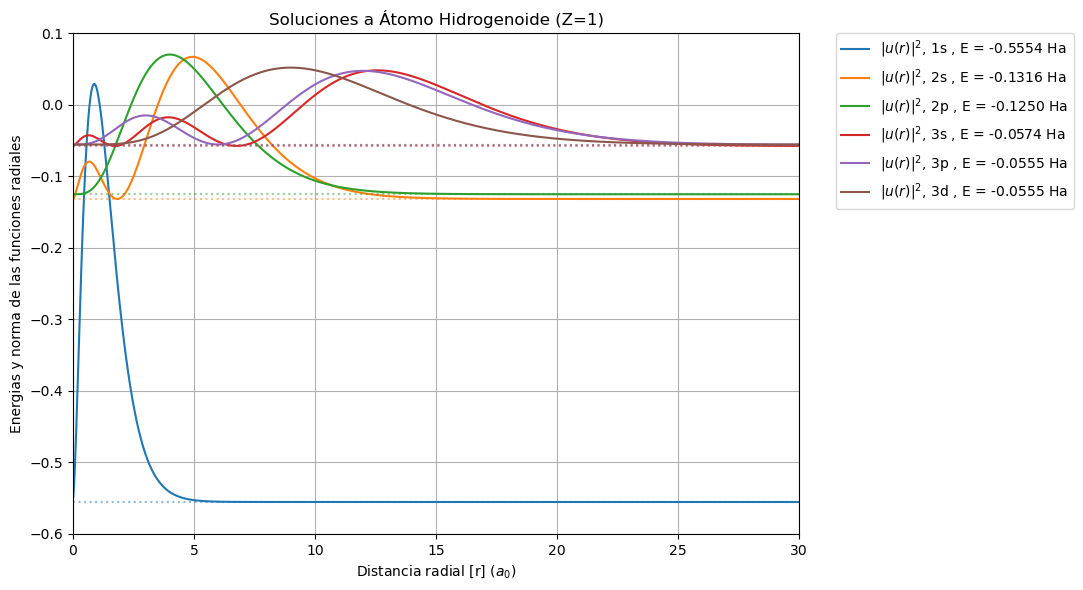

In [7]:
"""
SOLUCIÓN AL ÁTOMO HIDROGENOIDE.
Se resuelven los puntos 1, 2 y 3 de la actividad.
"""
# Variables de Simulación
L = 30.0
N = 1000

# Variables del Potencial
Z= 1 # Número Atómico
n_max = 3

# Simulación
print(f":::   SOLUCIÓN AL ÁTOMO HIDROGENOIDE PARA Z={Z}   ::: \n")
r = np.linspace(0.01, L, N)
orbitals = solve.get_orbitals_upto(n_max=3, r=r, N=N)
for orb in orbitals:
    E_teo = analytical.energy(orb['n'], Z=Z)
    error =  np.abs(orb['energy'] - E_teo) / abs(E_teo) * 100
    print(f"Orbital: {orb['label']:<3} | E_num = {orb['energy']:.6f} Ha | E_teo = {E_teo:.6f} Ha | Error: {error:.6f}%")
print("\n")
plot.solution(orbitals, r, xlim = (0,L), ylim = (-0.6, 0.1), label = f"Z={Z}")


:::   COMPARACIÓN DE SOLUCIONES NUMÉRICA Y ANALÍTICA PARA Z = 1   ::: 

Orbital: 1s  (n=1, l=0) | E_num = -0.555352 Ha | E_teo = -0.500000 Ha | Error: 0.055352 Ha (11.070450%)




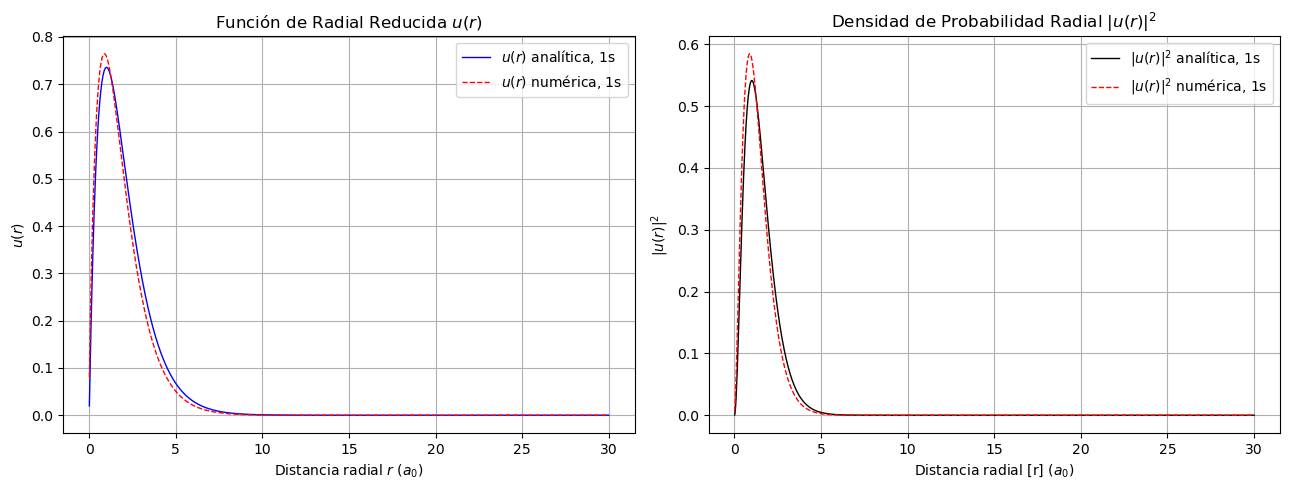

:::   COMPARACIÓN DE SOLUCIONES NUMÉRICA Y ANALÍTICA PARA Z = 1   ::: 

Orbital: 2p  (n=2, l=1) | E_num = -0.125002 Ha | E_teo = -0.125000 Ha | Error: 0.000002 Ha (0.001859%)




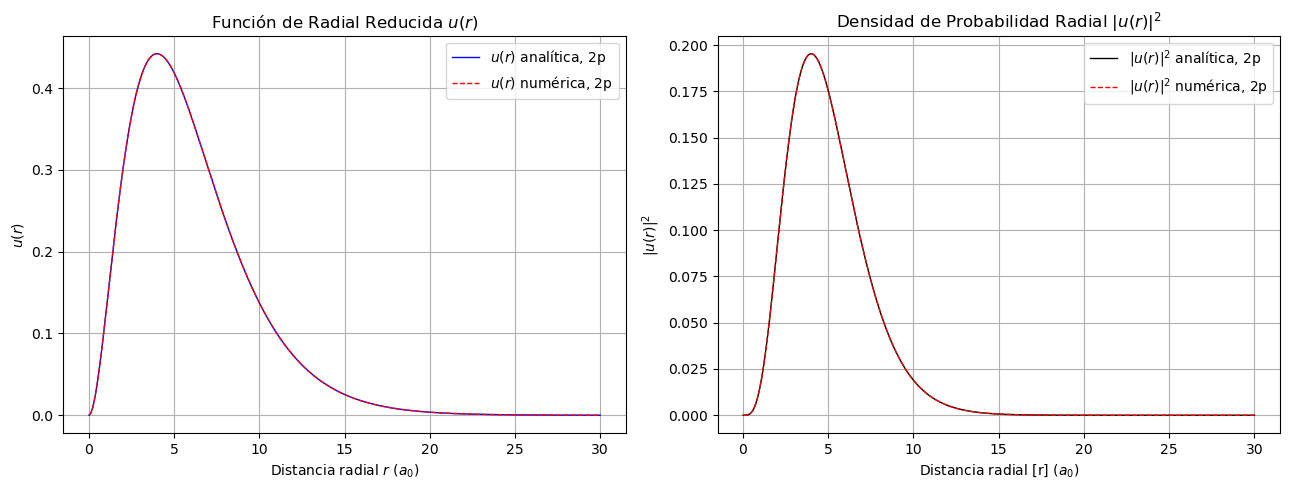

In [8]:
"""
COMPARACIÓN DE SOLUCIONES.
Se resuelve el punto 4 de la actividad.
"""
# Comparemos el estado base 1s (n = 1, l = 0)
compare.orbital(n=1, l=0, r=r, Z=Z, N=N)

# Comparemos también el primer estado exitado 2s (n=2, l=1)
compare.orbital(n=2, l=1, r=r, Z=Z, N=N)

In [9]:
"""
CORRECCIÓN DE ESTRUCTURA FINA.
Se  resuelven los puntos 5 y 6 de la actividad.
"""
s = 1/2
solve.fine_structure_upto(n_max= n_max, r=r, s=s, Z=Z, N=N)

:::   CORRECCIÓN DE ESTRUCTURA FINA PARA EL ESTADO 1S CON Z=1   :::
Para l=0, no hay acoplamiento espín-órbita. Por lo que no hay desdoblamiento 

:::   CORRECCIÓN DE ESTRUCTURA FINA PARA EL ESTADO 2S CON Z=1   :::
Para l=0, no hay acoplamiento espín-órbita. Por lo que no hay desdoblamiento 

:::   CORRECCIÓN DE ESTRUCTURA FINA PARA EL ESTADO 2P CON Z=1   :::
Valor numérico esperado de <1/r³>: 0.041669 a₀⁻³
Valor analítico esperado de <1/r³>: 0.041667 a₀⁻³ 

Energía del nivel 2P_1/2: -0.030206 meV
Energía del nivel 2P_3/2: 0.015103 meV
Separación energética de la estructura fina: 0.045309 meV (10.9556 GHz) 

:::   CORRECCIÓN DE ESTRUCTURA FINA PARA EL ESTADO 3S CON Z=1   :::
Para l=0, no hay acoplamiento espín-órbita. Por lo que no hay desdoblamiento 

:::   CORRECCIÓN DE ESTRUCTURA FINA PARA EL ESTADO 3P CON Z=1   :::
Valor numérico esperado de <1/r³>: 0.012527 a₀⁻³
Valor analítico esperado de <1/r³>: 0.012346 a₀⁻³ 

Energía del nivel 3P_1/2: -0.009081 meV
Energía del nivel 3P_3/2: 0.

:::   EFECTO ZEEMAN ANÓMALO PARA EL ORBITAL 2P con Z=1   ::: 



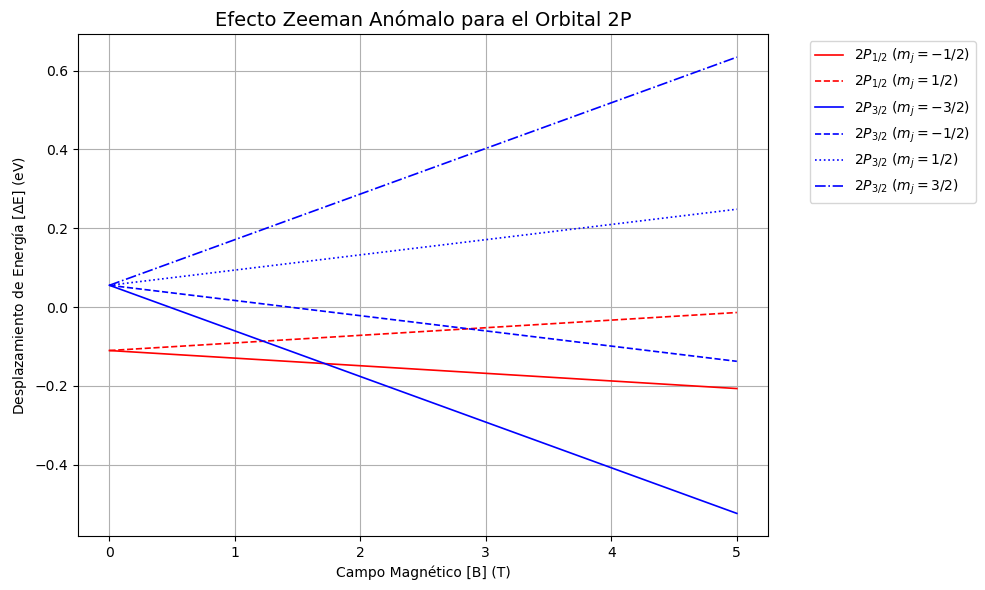

In [10]:
"""
EFECTO ZEEMAN ANÓMALO.
Se resuelve el punto 7 de la actividad.
"""
L, N = 5.0, 100 # Variables de Simulación
n, l, s = 2, 1, 1/2 # Números cuánticos del orbital (2P)

r = np.linspace(0.01, L, N)
B = np.linspace(0, L, N)

E2P_data = solve.get_orbital(n=n, l=l, r=r, Z=Z, N=N)
EFS_data = solve.fine_structure(n=2, l=1, r=r, s=s, Z=Z, N=N, verbose=False)

E_0 = E2P_data['energy'] * Ha_to_eV # Energía del orbital sin correcciones

J = (EFS_data['j1'], EFS_data['j2']) 
E_FS = (EFS_data['E1'], EFS_data['E2']) # Corrección de la estructura fina

plt.figure(figsize=(10, 6))
colors = ['red', 'blue']
linestyles = ['-', '--', ':', '-.']

print(f":::   EFECTO ZEEMAN ANÓMALO PARA EL ORBITAL {E2P_data['label'].upper()} con Z={Z}   ::: \n")

for idx_j, j in enumerate(J):
    color = colors[idx_j]  # Rojo para j1, Azul para j2
    for idx_m, m in enumerate(np.arange(-j, j + 1)):
        linestyle = linestyles[idx_m]
        
        gj = 1 + (j * (j + 1) + s * (s + 1) - l * (l + 1)) / (2 * j * (j + 1))
        E_Z = gj * mu_B_eV * B * m # Corrección Zeeman
        E_T = E_0 + E_FS[idx_j] + E_Z # Energía total
        E_R = E_FS[idx_j] + E_Z # Energía relativa
        
        #plt.plot(B, E_T, color=color, linestyle=linestyle, linewidth=1.2, label=f"$2P_{{{int(2*j)}/2}}$ ($m_j = {int(2*m)}/2$)") # Para Energía Total
        plt.plot(B, E_R*1e3, color=color, linestyle=linestyle, linewidth=1.2, label=f"$2P_{{{int(2*j)}/2}}$ ($m_j = {int(2*m)}/2$)") #Para Energy Shift

plt.title(f"Efecto Zeeman Anómalo para el Orbital {E2P_data['label'].upper()}", fontsize=14)
plt.xlabel("Campo Magnético [B] (T)")
#plt.ylabel("Energía Total [E] (eV)") # Para Energía Total
plt.ylabel(r"Desplazamiento de Energía [$\Delta$E] (eV)") # Para Enegy Shift
plt.grid()
plt.legend(bbox_to_anchor=(1.05, 1.0), loc='upper left', fontsize=10, frameon=True)

plt.tight_layout()
plt.show()